# 07 · สองทะเล (Q2) และการทดสอบความไวของข้อสรุป

| ทะเล | สถานี | สถานะในรายงาน |
| --- | --- | --- |
| อันดามัน | KO TAPHAO NOI | ตาม proposal |
| อ่าวไทย | KO LAK | **ส่วนขยายเกิน proposal §1.3** (proposal ระบุเป็นงานในอนาคต) ⇒ ตอบ Q2 |
| (อ่าวไทยตอนบน) | FORT PHRACHULA | หมายเหตุเท่านั้น — แผ่นดินทรุดรบกวน · ผลคำนวณครบแล้ว ไม่มีอะไรเกิน noise |

In [1]:
import json, sys
from pathlib import Path

import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "scripts"))

import make_figures as F
from wtc.plotting import use_thai_font
from wtc.series import VARIANTS, build_series

use_thai_font()
P = ROOT / "data" / "processed"
SEAS = ("ko_taphao_noi", "ko_lak")
SEA = {"ko_taphao_noi": "อันดามัน", "ko_lak": "อ่าวไทย"}
NAME = F.NAME
show = lambda name: display(Image(filename=str(ROOT / "figures" / "report" / f"{name}.png")))

q1 = np.load(P / "wtc_q1.npz", allow_pickle=True)
srch = np.load(P / "mwc_search.npz", allow_pickle=True)
nc = np.load(P / "null_control.npz", allow_pickle=True)
series = np.load(P / "series.npz", allow_pickle=True)
S1 = json.loads(str(q1["summary"]))
stats = json.loads(str(series["meta"]))["stats"]
idx = [str(s) for s in q1["indices"]]
print("ผลที่ใช้:", ", ".join(p.name for p in (P / "wtc_q1.npz", P / "mwc_search.npz", P / "null_control.npz")))

ผลที่ใช้: wtc_q1.npz, mwc_search.npz, null_control.npz


## 1. Q2 — อ่าวไทยกับอันดามันต่างกันไหม

### 1.1 ก่อนดู coherence: สัญญาณระหว่างปีของสองทะเลหน้าตาต่างกันตั้งแต่ต้น

                                 อันดามัน      อ่าวไทย
แนวโน้ม (mm/ปี)                      4.04         1.77
แอมพลิจูดวงรอบ 1 ปี (mm)               87          213
ฤดูกาลกินความแปรปรวน                  30%          81%
ความผันผวนที่เหลือ SD (mm)            112           73
ความจำ AR(1) ของ anomaly (a)         0.71         0.49
  ✅ figures/report/fig01_series.png


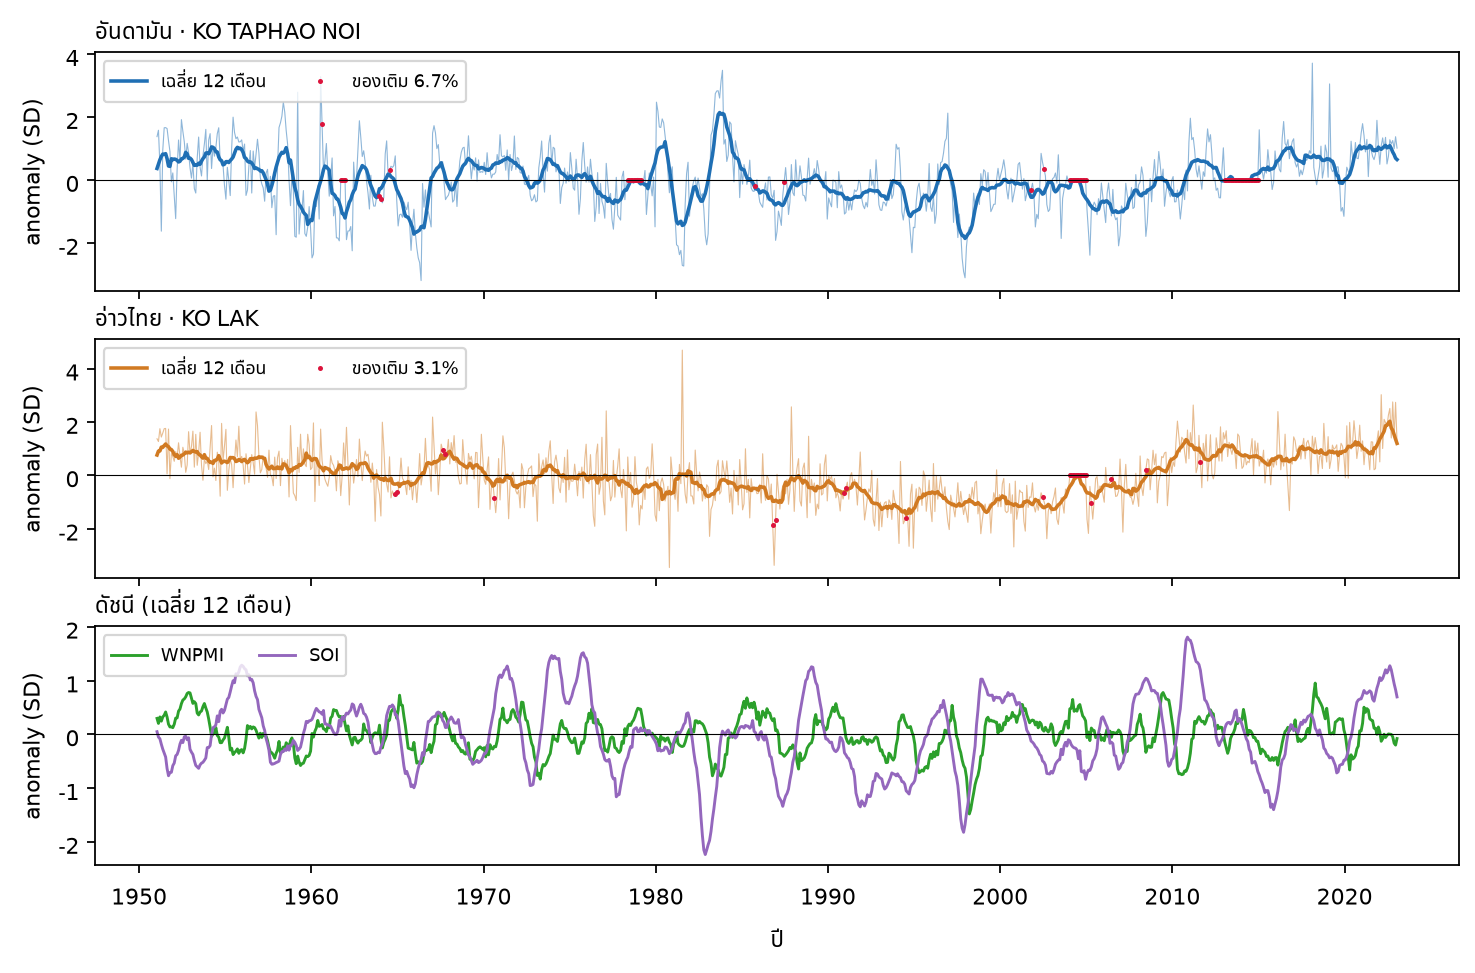

In [2]:
print(f"{'':28s} {'อันดามัน':>12s} {'อ่าวไทย':>12s}")
rows = (("แนวโน้ม (mm/ปี)", "slope", "{:.2f}"), ("แอมพลิจูดวงรอบ 1 ปี (mm)", "annual_amp", "{:.0f}"),
        ("ฤดูกาลกินความแปรปรวน", "frac_season", "{:.0%}"),
        ("ความผันผวนที่เหลือ SD (mm)", "resid_std", "{:.0f}"))
for lab_, k, fmt in rows:
    print(f"{lab_:28s} " + " ".join(f"{fmt.format(stats[s][k]):>12s}" for s in SEAS))
a_y = {s: float(q1["a_y"][[str(x) for x in q1["stations"]].index(s), 0]) for s in SEAS}
print(f"{'ความจำ AR(1) ของ anomaly (a)':28s} " + " ".join(f"{a_y[s]:12.2f}" for s in SEAS))
F.fig01_series(); show("fig01_series")

### 1.2 ดัชนีเดี่ยว (Q1 ของทั้งสองทะเล)


แถบ ทั้งระนาบ  —  PASC % (p) · ตัวหนาในรายงาน = p < 0.05
  ดัชนี            อันดามัน          อ่าวไทย
  SOI         13.9 (0.002)*     4.0 (0.628) 
  WNPMI       13.5 (0.002)*     4.7 (0.490) 
  DMI         13.2 (0.004)*     4.6 (0.501) 
  Niño3.4     10.2 (0.018)*     2.5 (0.951) 
  AMO          8.2 (0.078)      6.6 (0.186) 
  TPI          7.0 (0.176)      3.4 (0.791) 
  NAO          5.1 (0.390)      6.5 (0.189) 
  PDO          2.9 (0.889)      3.4 (0.830) 

แถบ 2–7 ปี  —  PASC % (p) · ตัวหนาในรายงาน = p < 0.05
  ดัชนี            อันดามัน          อ่าวไทย
  WNPMI       32.4 (0.001)*     4.3 (0.454) 
  DMI         17.2 (0.026)*     3.3 (0.578) 
  SOI         15.5 (0.038)*     1.2 (0.820) 
  AMO         14.0 (0.048)*    14.0 (0.051) 
  Niño3.4     13.9 (0.052)      0.3 (0.921) 
  TPI         10.8 (0.114)      0.0 (0.955) 
  NAO          8.4 (0.201)      7.8 (0.233) 
  PDO          1.3 (0.793)      0.6 (0.882) 


  ✅ figures/report/fig04_q1_pasc.png


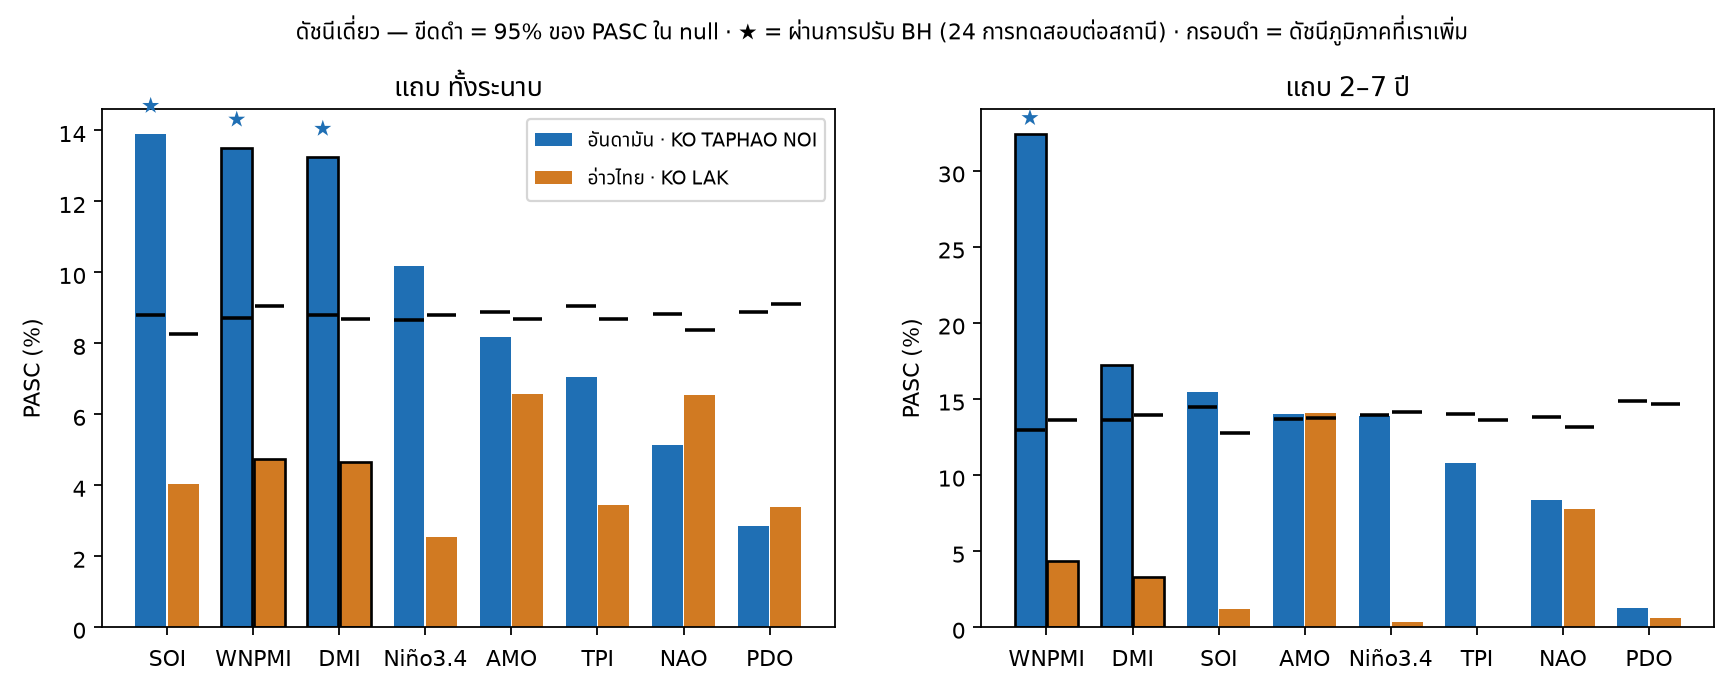

  ✅ figures/report/fig03_wtc_maps.png


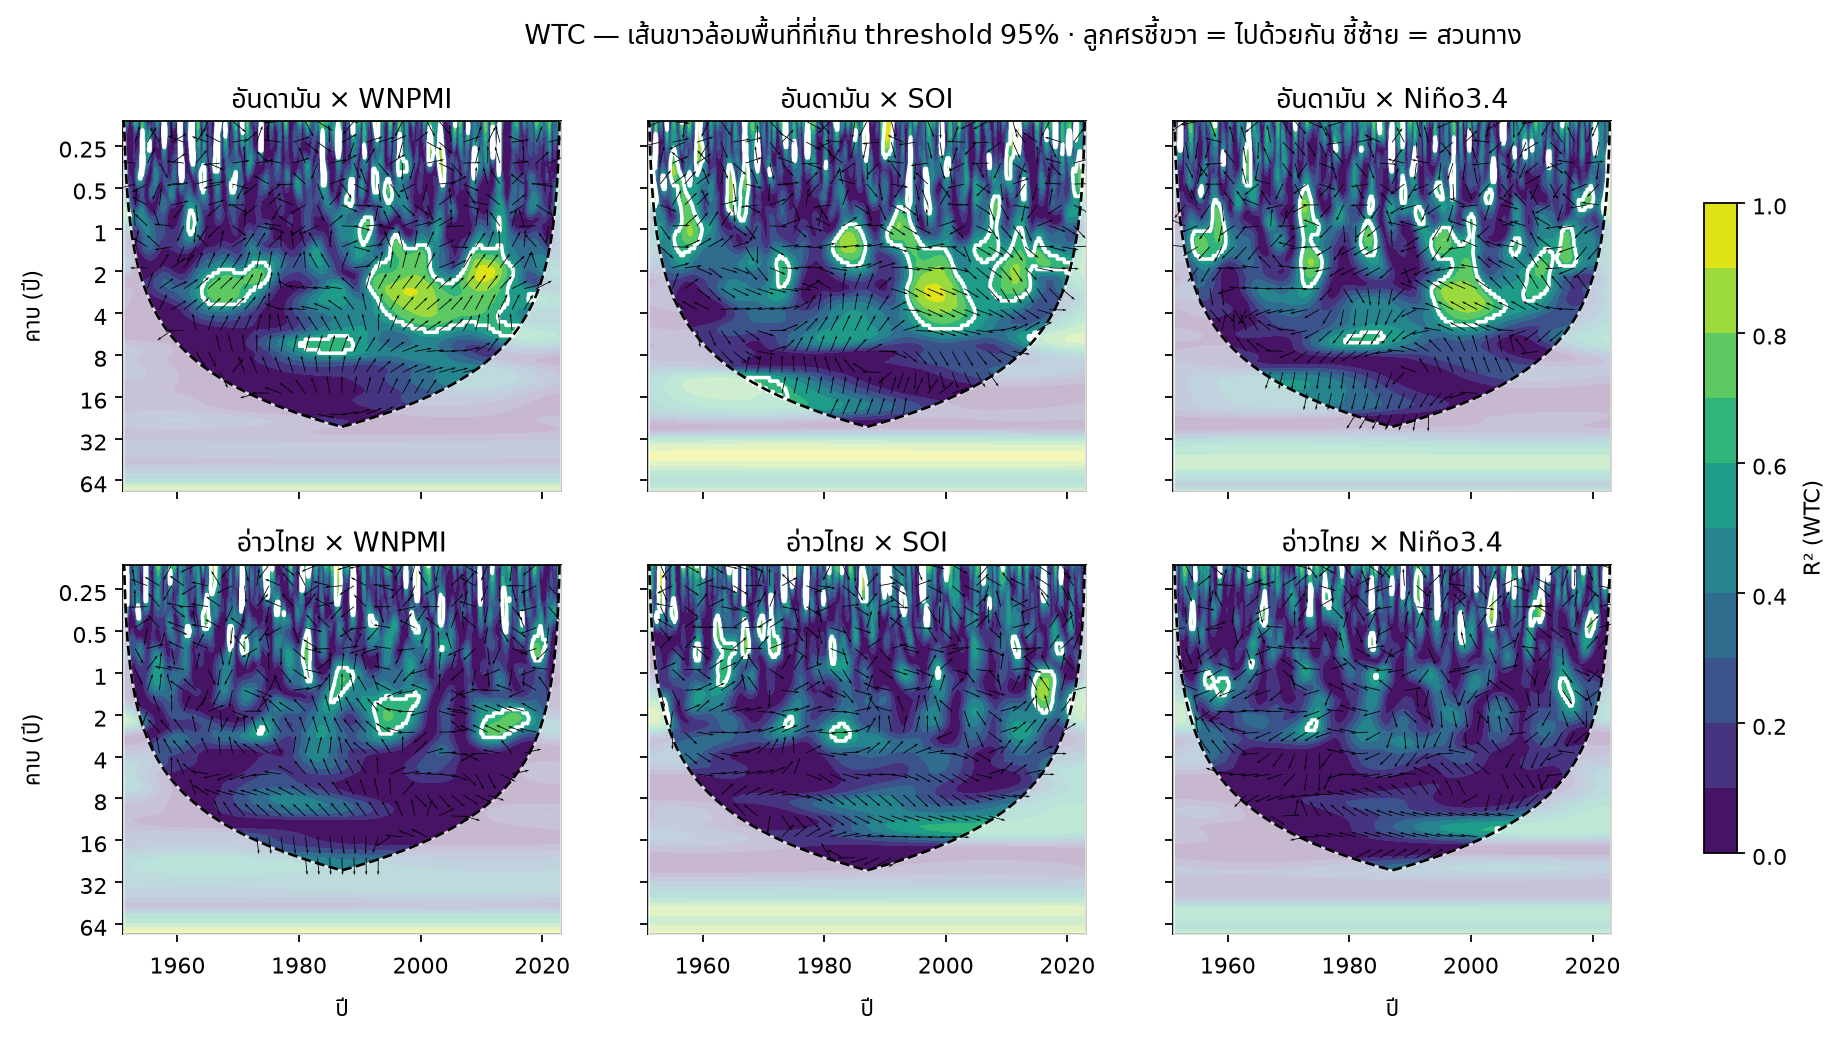

In [3]:
bands = [str(b) for b in q1["bands"]]
for b in ("ทั้งระนาบ", "2–7 ปี"):
    print(f"\nแถบ {b}  —  PASC % (p) · ตัวหนาในรายงาน = p < 0.05")
    print(f"  {'ดัชนี':8s} " + " ".join(f"{SEA[s]:>16s}" for s in SEAS))
    for k in sorted(idx, key=lambda k: -S1["ko_taphao_noi"][k][b]["pasc"]):
        cells = []
        for s in SEAS:
            r = S1[s][k][b]
            cells.append(f"{r['pasc']:6.1f} ({r['p']:.3f}){'*' if r['p'] < 0.05 else ' '}")
        print(f"  {NAME[k]:8s} " + " ".join(f"{c:>16s}" for c in cells))
F.fig04_q1_pasc(); show("fig04_q1_pasc")
F.fig03_wtc_maps(); show("fig03_wtc_maps")

### 1.3 การรวมหลายดัชนี (Q3–Q5 ของทั้งสองทะเล)

อันดามัน  แถบ ทั้งระนาบ ชุดที่ดีที่สุดจาก 218 ชุด: SOI+AMO+DMI                   15.1% · p ทั้งตระกูล 0.020 · 95% ของ null 13.8%
อันดามัน  แถบ 2–7 ปี    ชุดที่ดีที่สุดจาก 218 ชุด: WNPMI                         32.2% · p ทั้งตระกูล 0.006 · 95% ของ null 25.5%
อ่าวไทย   แถบ ทั้งระนาบ ชุดที่ดีที่สุดจาก 218 ชุด: Niño3.4+SOI+DMI                8.9% · p ทั้งตระกูล 0.591 · 95% ของ null 14.0%
อ่าวไทย   แถบ 2–7 ปี    ชุดที่ดีที่สุดจาก 218 ชุด: Niño3.4+AMO                   14.6% · p ทั้งตระกูล 0.503 · 95% ของ null 24.0%


  ✅ figures/report/fig06_q6_false_floor.png


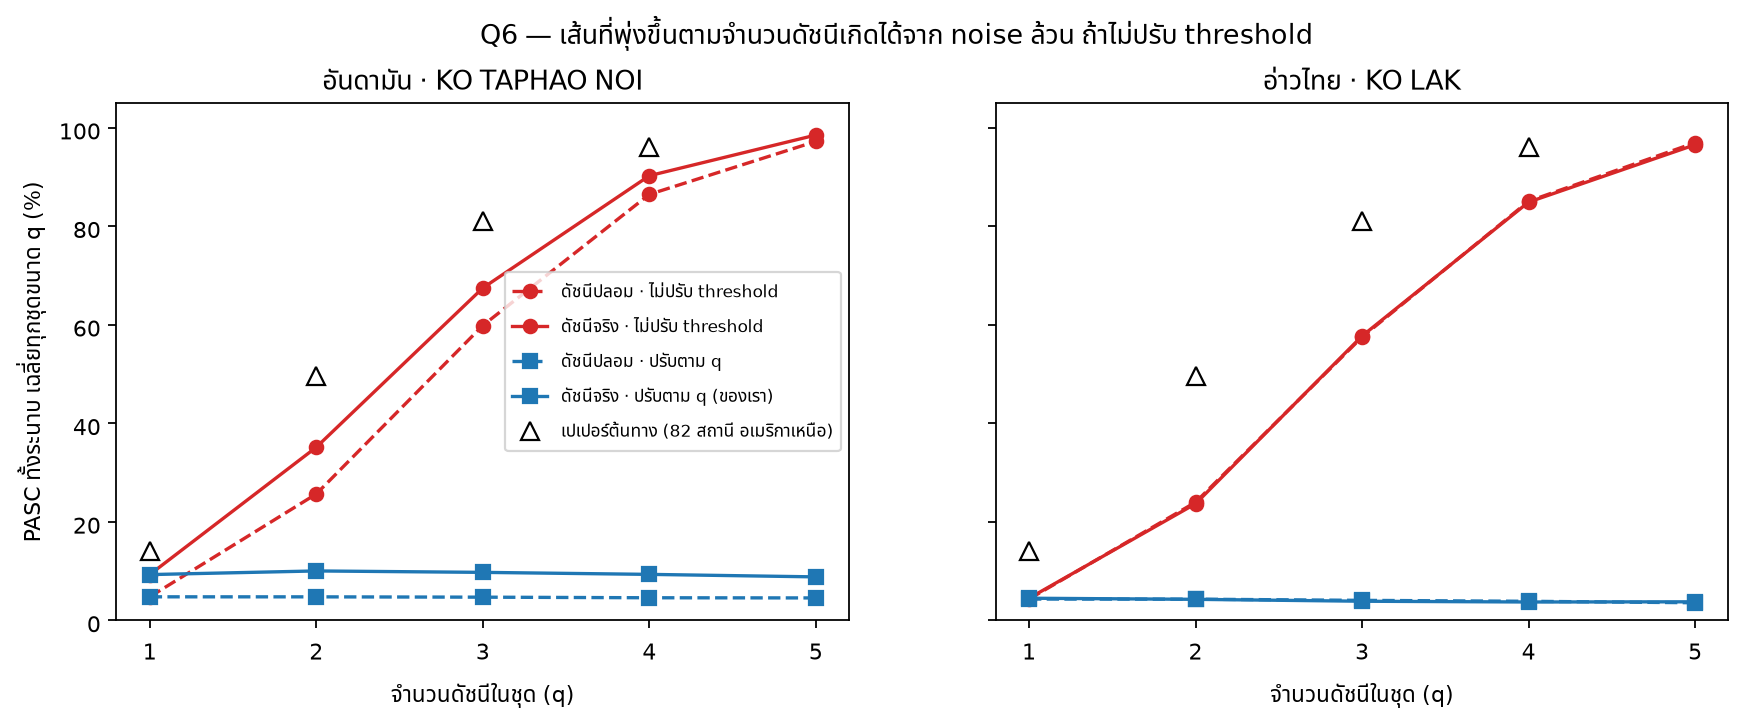

  ✅ figures/report/fig07_q3_best_per_q.png


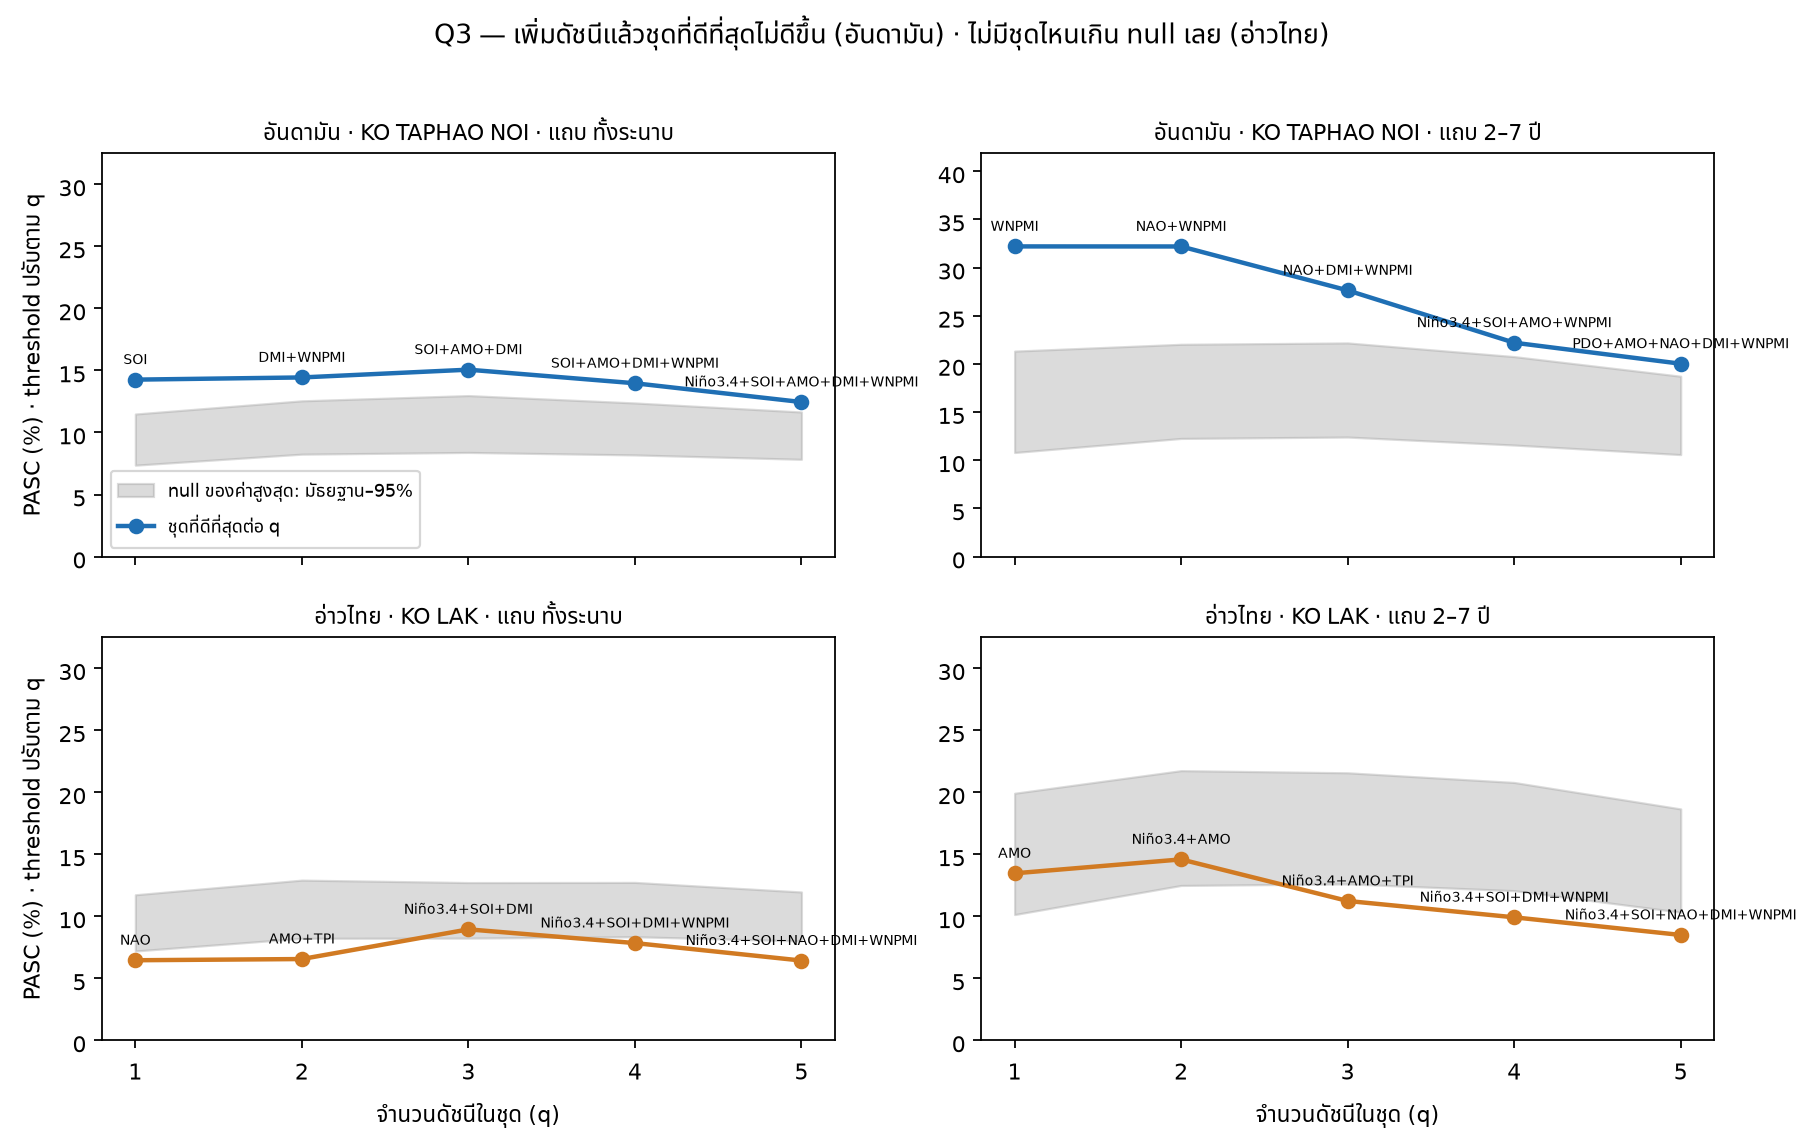

  ✅ figures/report/fig08_q5_regional.png


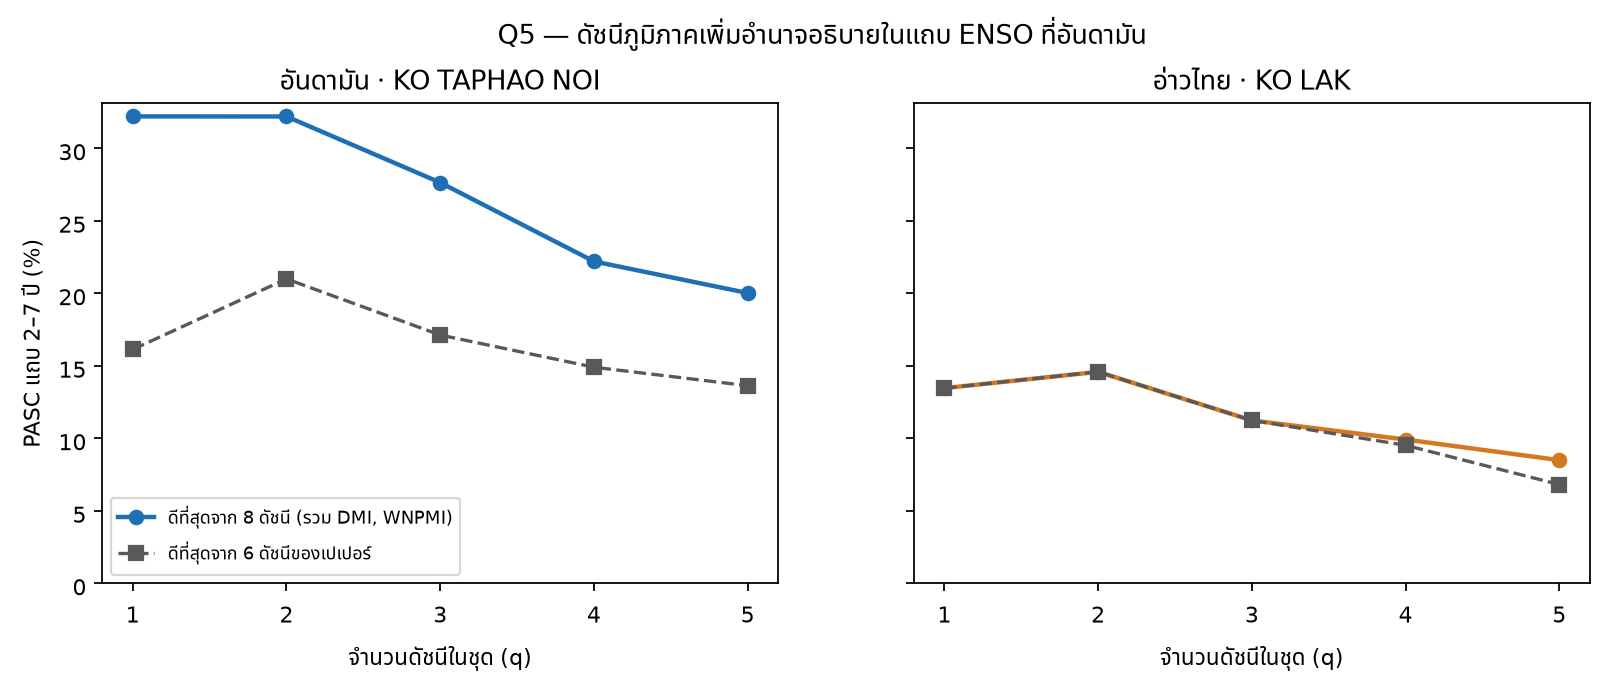

In [4]:
kbs = {b: [str(x) for x in srch["bands"]].index(b) for b in ("ทั้งระนาบ", "2–7 ปี")}
subsets = [tuple(s) for s in json.loads(str(srch["subsets"]))]
dy = [str(x) for x in nc["designs"]].index("fake_y")
pval = lambda o, n: float((np.sum(n >= o - 1e-9) + 1) / (len(n) + 1))
for s in SEAS:
    si = [str(x) for x in srch["stations"]].index(s); ni = [str(x) for x in nc["stations"]].index(s)
    for b, kb in kbs.items():
        v = srch["pasc"][si][:, kb]; top = int(np.nanargmax(v))
        nmax = np.nanmax(nc["pasc"][ni, dy][:, :, kb], axis=1)
        print(f"{SEA[s]:9s} แถบ {b:9s} ชุดที่ดีที่สุดจาก 218 ชุด: {F.lab(subsets[top]):28s} {v[top]:5.1f}% · "
              f"p ทั้งตระกูล {pval(v[top], nmax):.3f} · 95% ของ null {np.percentile(nmax, 95):.1f}%")
for name in ("fig06_q6_false_floor", "fig07_q3_best_per_q", "fig08_q5_regional"):
    getattr(F, name)(); show(name)

## 2. การทดสอบความไว

| แบบ | เปลี่ยนอะไร | ตอบความกังวลไหน |
| --- | --- | --- |
| `baseline` | แบบมาตรฐาน | แบบมาตรฐาน (ใช้ตรวจว่าสายใหม่ได้เลขเท่า W6) |
| `interp_all` | interp ทุกช่องว่าง | แบบมาตรฐานเติม 0 ในช่องว่างยาว — ถ้า interp แทน ข้อสรุปเปลี่ยนไหม |
| `fill25` | เกณฑ์ของเติม 25% | นับเฉพาะจุดที่ของเติมในหน้าต่างไม่เกิน 25% (แบบมาตรฐาน 50%) |
| `cut_2004` | ตัดปี 2004–2005 | ปีสึนามิ มาตรวัดเสียหาย — ทำให้เป็นช่องว่างทั้งสองปีแล้วไม่นับ |
| `no_amo` | ตัด AMO (ยาวถึง 2025) | AMO จบปี 2023 เป็นตัวจำกัดท้ายหน้าต่าง — ตัดออกแล้วข้อมูลยาวขึ้น |
| `short_1985` | PSMSL ช่วง 1985–2019 | คู่เทียบของ y_q7: ความยาวเท่ากันแต่ยังใช้ PSMSL ⇒ แยกผลของ 'ข้อมูลสั้นลง' ออกจากผลของ 'เปลี่ยนแหล่งข้อมูล' |
| `pre_2006` | PSMSL ก่อน 2006 (1951–2005) | เพิ่ม 2026-10-07 หลังเห็นผลของ y_q7: PSMSL กับ UHSLC ของ KO TAPHAO NOI ตรงกันระดับ mm ถึงปี 2005 แล้วแยกทางกัน ⇒ ตัดช่วงที่น่าสงสัยทิ้งทั้งหมด ดูว่าข้อสรุปยังอยู่ไหม |
| `y_q7` | Y จากโซ่ Q7 (UHSLC 1985–2019) | PSMSL ของ KO TAPHAO NOI มีขั้นบันได datum −100.7 mm ที่ไม่มีเอกสาร — ใช้ UHSLC ผ่านตัวกรองที่เราออกแบบเองแทน (เทียบกับ short_1985) |

In [5]:
SENS = {}
for n in VARIANTS:
    f = P / f"sens_{n}.npz"
    if f.exists():
        z = np.load(f, allow_pickle=True)
        SENS[n] = dict(summary=json.loads(str(z["summary"])), meta=json.loads(str(z["meta"])), z=z)
print("แบบที่มีผล:", ", ".join(SENS))
assert set(SENS) == set(VARIANTS), f"ขาด {set(VARIANTS) - set(SENS)}"
assert all(SENS[n]["meta"]["nmc"] == 1000 and SENS[n]["meta"]["nrep"] == 1000 for n in SENS)

z = SENS["baseline"]["z"]
for s in SEAS:
    si = [str(x) for x in srch["stations"]].index(s)
    np.testing.assert_array_equal(z[f"{s}__pasc"], srch["pasc"][si])
print("✅ baseline ของการทดสอบความไว = mwc_search.npz ทุกชุดทุกแถบ ทั้งสองทะเล")

แบบที่มีผล: baseline, interp_all, fill25, cut_2004, no_amo, short_1985, pre_2006, y_q7
✅ baseline ของการทดสอบความไว = mwc_search.npz ทุกชุดทุกแถบ ทั้งสองทะเล


In [6]:
def row(n, s, b, k):
    rec = SENS[n]["summary"].get(s, {}).get("bands", {}).get(b, {}).get("single", {}).get(k)
    return "        —" if rec is None else f"{rec['pasc']:5.1f}{'*' if rec['p'] < 0.05 else ' '}({rec['p']:.3f})"

for s in SEAS:
    print(f"\n{'=' * 118}\n{SEA[s]}  —  PASC % (p ต่อชุด) · * = p < 0.05")
    print(f"  {'แบบ':30s} {'n':>4s} │ {'WNPMI 2–7':>14s} {'SOI 2–7':>14s} {'Niño3.4 2–7':>14s} {'SOI ทั้งระนาบ':>14s} │ "
          f"{'พอที่ (ทั้ง/2–7)':>14s} │ {'ประหยัดสุด 2–7 (p ทั้งตระกูล)':32s} │ {'8−6 2–7 (p)':>13s}")
    for n in SENS:
        sm = SENS[n]["summary"].get(s)
        if sm is None:
            continue
        b27, bw = sm["bands"]["2–7 ปี"], sm["bands"]["ทั้งระนาบ"]
        pars = b27["parsimonious"]
        print(f"  {SENS[n]['meta']['label']:30s} {SENS[n]['meta']['n']:4d} │ {row(n, s, '2–7 ปี', 'wnpmi'):>14s} "
              f"{row(n, s, '2–7 ปี', 'soi'):>14s} {row(n, s, '2–7 ปี', 'nino34'):>14s} {row(n, s, 'ทั้งระนาบ', 'soi'):>14s} │ "
              f"{bw['q_enough']:>6d} / {b27['q_enough']:<5d} │ {F.lab(pars['subset']):22s} {pars['pasc']:5.1f} ({pars['p_family']:.3f}) │ "
              f"{b27['q5_gain']['observed']:+5.1f} ({b27['q5_gain']['p']:.3f})")


อันดามัน  —  PASC % (p ต่อชุด) · * = p < 0.05
  แบบ                               n │      WNPMI 2–7        SOI 2–7    Niño3.4 2–7  SOI ทั้งระนาบ │ พอที่ (ทั้ง/2–7) │ ประหยัดสุด 2–7 (p ทั้งตระกูล)    │   8−6 2–7 (p)
  แบบมาตรฐาน                      865 │   32.2*(0.001)   16.1*(0.025)   13.3 (0.056)   14.3*(0.002) │      1 / 1     │ WNPMI                   32.2 (0.006) │ +11.2 (0.022)
  interp ทุกช่องว่าง              865 │   28.0*(0.001)   24.8*(0.002)   18.6*(0.011)   15.8*(0.001) │      1 / 2     │ DMI+WNPMI               35.0 (0.001) │  +8.5 (0.058)
  เกณฑ์ของเติม 25%                865 │   31.4*(0.001)   15.7*(0.027)   13.3 (0.056)   13.9*(0.003) │      1 / 1     │ NAO+WNPMI               32.5 (0.006) │ +11.3 (0.023)
  ตัดปี 2004–2005                 865 │   22.5*(0.003)   13.8*(0.046)   12.5 (0.068)   13.1*(0.003) │      1 / 1     │ NAO+DMI+WNPMI           27.5 (0.029) │  +6.5 (0.111)
  ตัด AMO (ยาวถึง 2025)           900 │   35.1*(0.002)   16.7*(0.023)   13.0 (0.052)   14.3*(0.

  ✅ figures/report/fig09_sensitivity.png


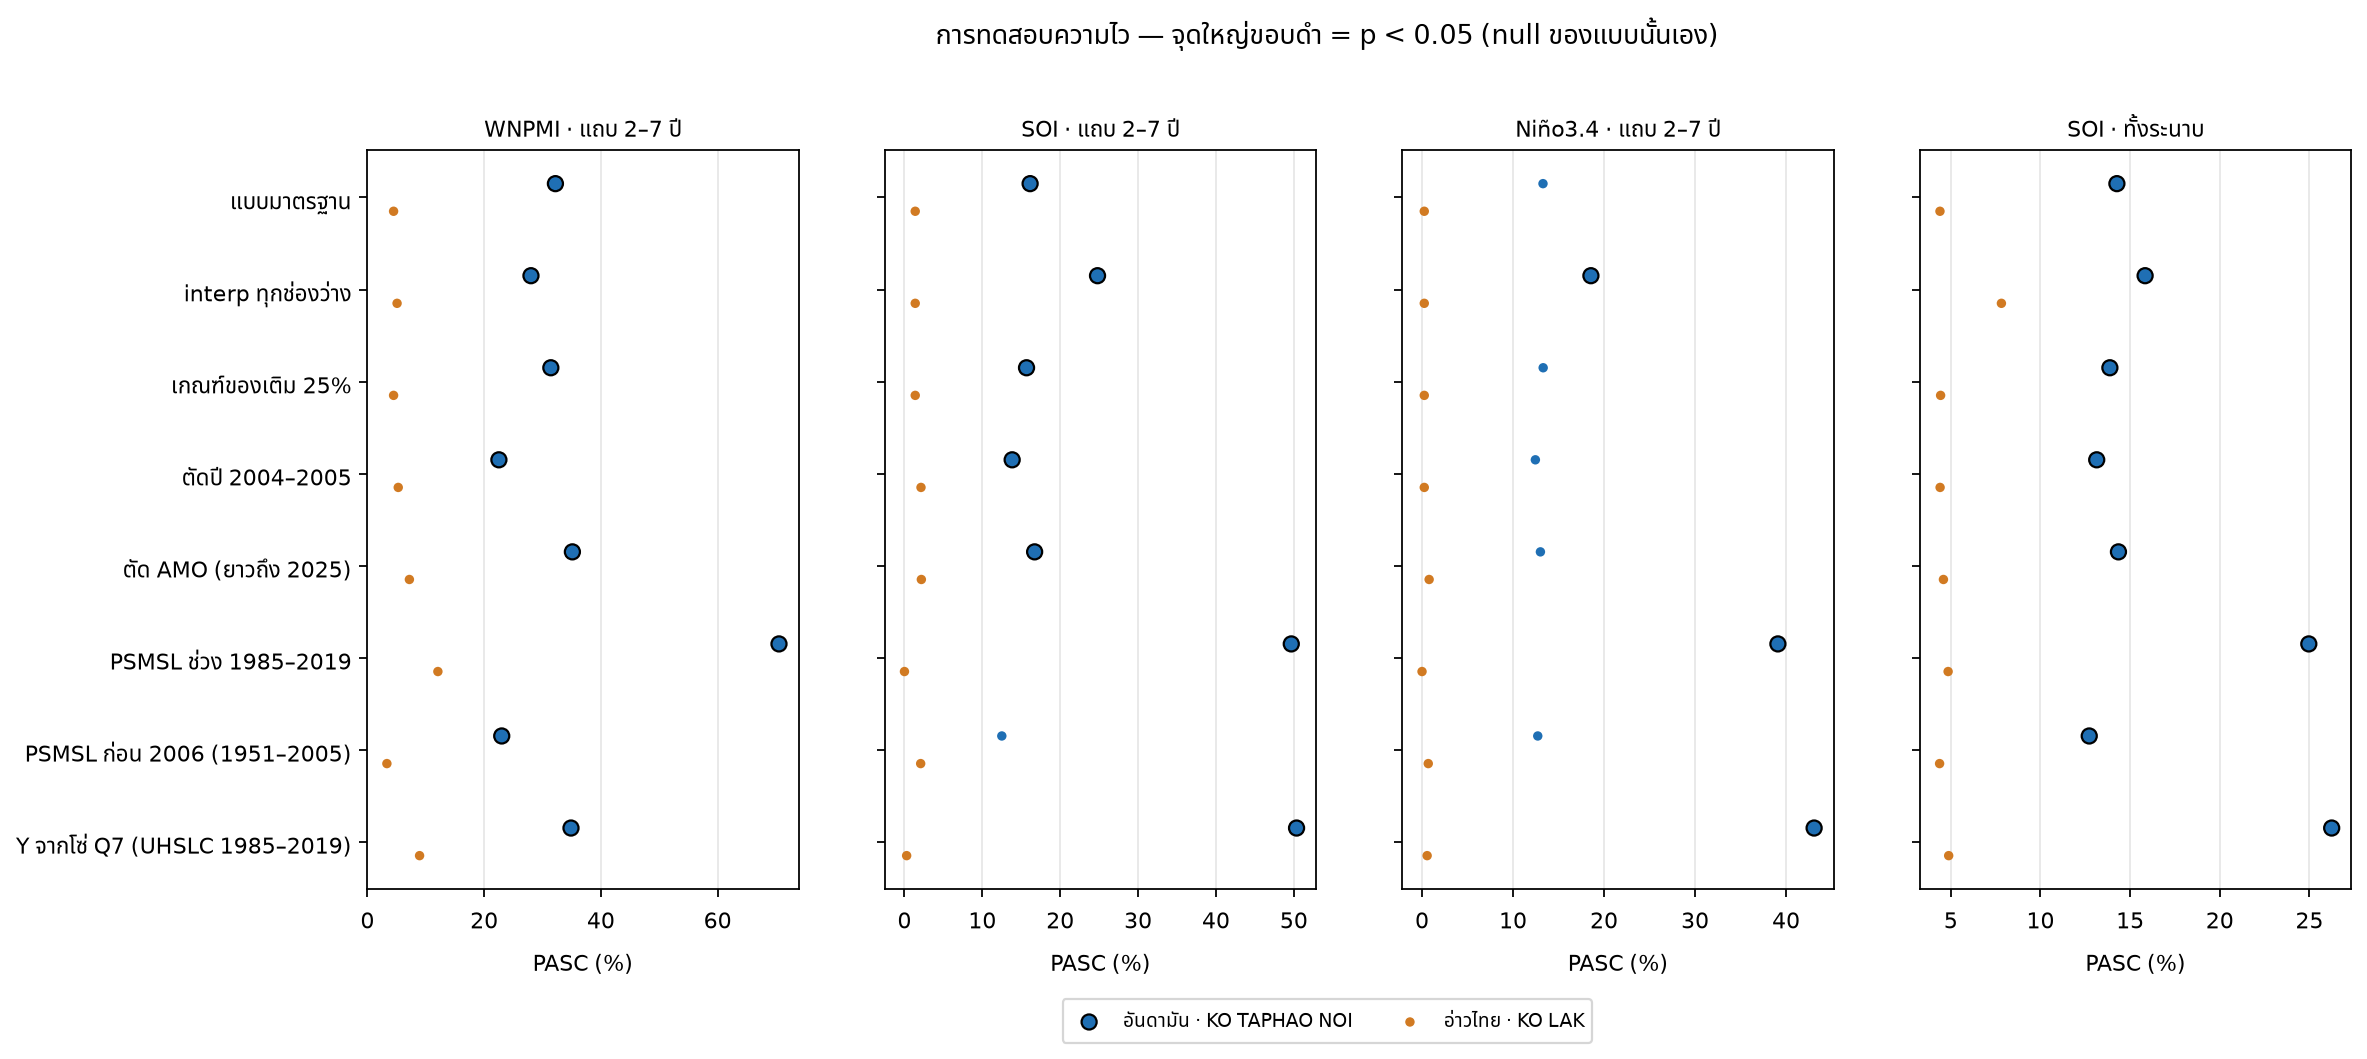

In [7]:
F.fig09_sensitivity(); show("fig09_sensitivity")

### 2.1 แยกผลของ "ช่วงเวลา" ออกจากผลของ "ปัญหา datum" (อันดามัน)

In [8]:
s = "ko_taphao_noi"
print(f"{'':12s} {'baseline (1951–2023)':>22s} {'short_1985 (PSMSL)':>20s} {'y_q7 (UHSLC)':>16s}")
for b, k in (("2–7 ปี", "wnpmi"), ("2–7 ปี", "soi"), ("2–7 ปี", "nino34"), ("2–7 ปี", "dmi"),
             ("ทั้งระนาบ", "soi"), ("ทั้งระนาบ", "wnpmi")):
    print(f"{NAME[k] + ' ' + b:18s} " + " ".join(f"{row(n, s, b, k):>18s}" for n in ("baseline", "short_1985", "y_q7")))

               baseline (1951–2023)   short_1985 (PSMSL)     y_q7 (UHSLC)
WNPMI 2–7 ปี             32.2*(0.001)       70.5*(0.001)       34.9*(0.003)
SOI 2–7 ปี               16.1*(0.025)       49.7*(0.001)       50.3*(0.001)
Niño3.4 2–7 ปี           13.3 (0.056)       39.1*(0.001)       43.1*(0.001)
DMI 2–7 ปี               17.7*(0.013)       22.0*(0.031)       23.3*(0.024)
SOI ทั้งระนาบ            14.3*(0.002)       25.0*(0.001)       26.2*(0.001)
WNPMI ทั้งระนาบ          13.3*(0.003)       28.0*(0.001)       17.5*(0.001)


## สรุป W7

### Q2 — อ่าวไทยกับอันดามันต่างกันจริงไหม: **ต่างกันชัดเจน และเป็นข้อสรุปที่แข็งแรงที่สุดของงาน**

### ความแข็งแรงของข้อสรุปของอันดามัน (8 แบบ)

| ข้อสรุป | ผล | สถานะ |
| --- | --- | --- |
| มี coherence เกิน noise กับ SOI · DMI · WNPMI · Niño3.4 (ทั้งระนาบ) | ทั้งสี่ตัว p < 0.05 ใน **8/8 แบบ** (p ต่อดัชนี ยังไม่ปรับหลายการทดสอบ · ในแบบมาตรฐาน Niño3.4 ไม่รอด BH) | ✅ แข็งแรง |
| ดัชนีเดียวพอ (Q3) เมื่อดูทั้งระนาบ | 8/8 | ✅ แข็งแรง |
| ดัชนีเดียวพอ (Q3) ในแถบ 2–7 ปี | 5/8 (interp_all · pre_2006 · y_q7 ได้ +7 ถึง +10 จุดจากตัวที่สอง) | 🟡 ขึ้นกับการเตรียมข้อมูล |
| **WNPMI นำในแถบ 2–7 ปี** | อันดับ 1 ใน 6/8 · pre_2006 เสมอกับ DMI (23.9 / 23.0) · y_q7 ตกไปอันดับ 3 · PASC แกว่ง 22–70% | 🟡 ไม่แข็งแรง |
| ดัชนีภูมิภาคเพิ่มอำนาจอธิบาย (Q5) ในแถบ 2–7 ปี | p < 0.05 ใน 4/8 · ก้ำกึ่ง (0.055–0.058) 2/8 · ไม่มีเลยใน y_q7 | 🟡 มีแนวโน้ม แต่ไม่แข็งแรง |
| threshold ต้องปรับตามจำนวนดัชนี / เส้นของเปเปอร์ต้นทางเกิดได้จาก noise (Q6) | เป็นสมบัติของวิธี ไม่ขึ้นกับข้อมูล · threshold แทบเท่ากันทุกแบบ (0.59 → 0.96) | ✅ แข็งแรง |

### ⚠️ ข้อค้นพบใหม่ที่ต้องเขียนในรายงาน — คุณภาพของข้อมูล PSMSL หลังปี 2005